<a href="https://colab.research.google.com/github/romandudarets/Data-Analysis-University/blob/main/%D0%9B%D1%8010_%D0%94%D1%83%D0%B4%D0%B0%D1%80%D0%B5%D1%86%D1%8C_4_9_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  
**Прізвище, ім’я:** Дударець Роман Богданович  
**Група:** 4-9  
**Дата:** 22.11.2026

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import classification_report, confusion_matrix

np.random.seed(42)
tf.random.set_seed(42)
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot",
]

print("x_train shape:", x_train.shape, "| y_train shape:", y_train.shape)
print("x_test shape: ", x_test.shape,  "| y_test shape: ", y_test.shape)


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
x_train shape: (60000, 28, 28) | y_train shape: (60000,)
x_test shape:  (10000, 28, 28) | y_test shape:  (10000,)


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

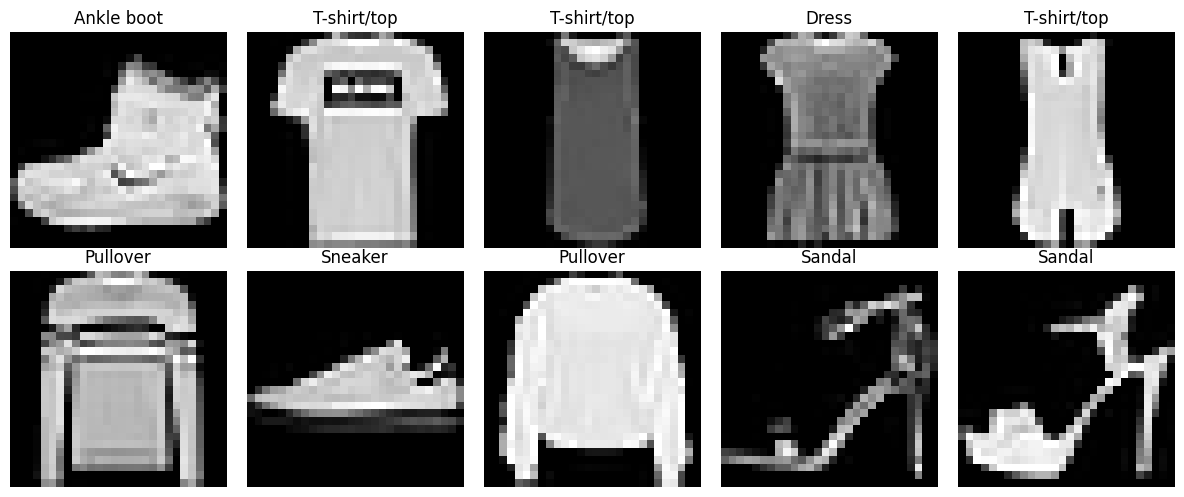

In [3]:
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(class_names[int(y_train[i])])
    plt.axis("off")
plt.tight_layout()
plt.show()


### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [4]:
x_train_norm = x_train.astype("float32") / 255.0
x_test_norm = x_test.astype("float32") / 255.0

print("x_train_norm dtype:", x_train_norm.dtype, "| min/max:", x_train_norm.min(), x_train_norm.max())
print("x_test_norm dtype: ", x_test_norm.dtype,  "| min/max:", x_test_norm.min(), x_test_norm.max())

x_train_norm dtype: float32 | min/max: 0.0 1.0
x_test_norm dtype:  float32 | min/max: 0.0 1.0


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

In [5]:
learning_rate = 0.001

model_1 = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(10, activation="softmax"),
])

model_1.compile(
    optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)


### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [6]:
early_stop_1 = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1,
)

reduce_lr_1 = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1,
)

history_1 = model_1.fit(
    x_train_norm,
    y_train,
    epochs=25,
    batch_size=128,
    validation_split=0.2,
    callbacks=[early_stop_1, reduce_lr_1],
    verbose=1,
)


Epoch 1/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.7738 - loss: 0.6338 - val_accuracy: 0.8413 - val_loss: 0.4331 - learning_rate: 0.0010
Epoch 2/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.8401 - loss: 0.4410 - val_accuracy: 0.8568 - val_loss: 0.3904 - learning_rate: 0.0010
Epoch 3/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.8565 - loss: 0.3963 - val_accuracy: 0.8635 - val_loss: 0.3667 - learning_rate: 0.0010
Epoch 4/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8637 - loss: 0.3699 - val_accuracy: 0.8696 - val_loss: 0.3573 - learning_rate: 0.0010
Epoch 5/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8698 - loss: 0.3542 - val_accuracy: 0.8681 - val_loss: 0.3587 - learning_rate: 0.0010
Epoch 6/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.8743 - loss: 0.3404 - val_accuracy: 0.8762 - val_loss: 0.3407 - learning_rate: 0.0010
Epoch 7/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8782 - loss: 0.32

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [7]:
print("Кількість шарів у моделі:", len(model_1.layers))
model_1.summary()

Кількість шарів у моделі: 6


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705,440 (2.69 MB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 470,294 (1.79 MB)

### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [8]:
# Якщо потрібно зберегти на Google Drive, розкоментуйте два рядки нижче:
# from google.colab import drive
# drive.mount("/content/drive")

model_1.save("fashion_mnist_model_1.keras")
print("Модель збережено у fashion_mnist_model_1.keras")


Модель збережено у fashion_mnist_model_1.keras


### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

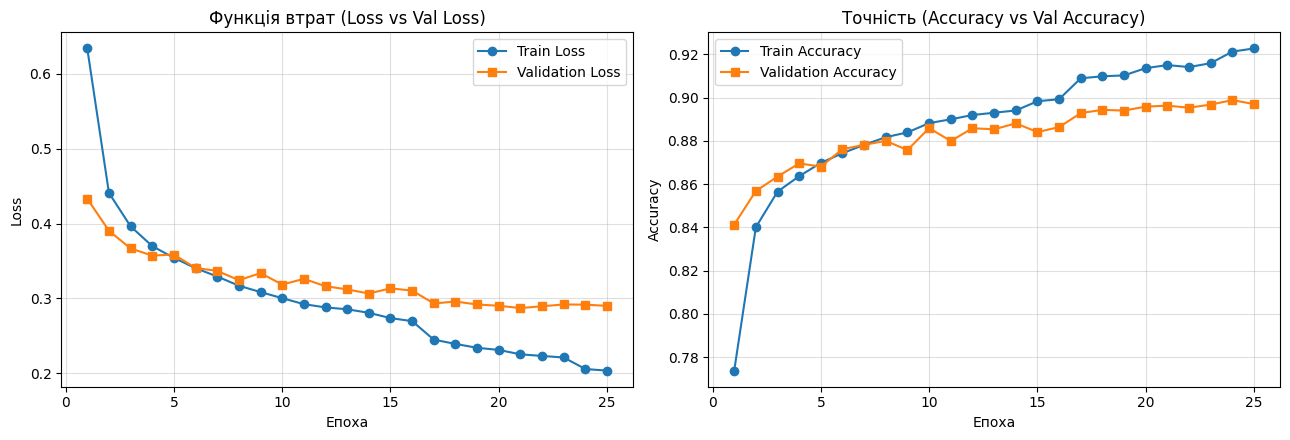

In [9]:
epochs_range_1 = range(1, len(history_1.history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(epochs_range_1, history_1.history["loss"], marker="o", label="Train Loss")
axes[0].plot(epochs_range_1, history_1.history["val_loss"], marker="s", label="Validation Loss")
axes[0].set_title("Функція втрат (Loss vs Val Loss)")
axes[0].set_xlabel("Епоха")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.4)

axes[1].plot(epochs_range_1, history_1.history["accuracy"], marker="o", label="Train Accuracy")
axes[1].plot(epochs_range_1, history_1.history["val_accuracy"], marker="s", label="Validation Accuracy")
axes[1].set_title("Точність (Accuracy vs Val Accuracy)")
axes[1].set_xlabel("Епоха")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.4)

plt.tight_layout()
plt.show()


### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [10]:
test_loss_1, test_acc_1 = model_1.evaluate(x_test_norm, y_test, verbose=0)
y_pred_probs_1 = model_1.predict(x_test_norm, verbose=0)
y_pred_1 = np.argmax(y_pred_probs_1, axis=1)

print(f"Test Loss:     {test_loss_1:.4f}")
print(f"Test Accuracy: {test_acc_1:.4f}")
print(f"Поріг 0.87 виконано: {'ТАК' if test_acc_1 >= 0.87 else 'НІ'}\n")
print(classification_report(y_test, y_pred_1, target_names=class_names, digits=4))


Test Loss:     0.3160
Test Accuracy: 0.8904
Поріг 0.87 виконано: ТАК

              precision    recall  f1-score   support

 T-shirt/top     0.8647    0.8120    0.8375      1000
     Trouser     0.9898    0.9730    0.9813      1000
    Pullover     0.7916    0.8280    0.8094      1000
       Dress     0.8922    0.8940    0.8931      1000
        Coat     0.7982    0.8190    0.8085      1000
      Sandal     0.9796    0.9600    0.9697      1000
       Shirt     0.7127    0.7220    0.7173      1000
     Sneaker     0.9407    0.9680    0.9542      1000
         Bag     0.9817    0.9680    0.9748      1000
  Ankle boot     0.9639    0.9600    0.9619      1000

    accuracy                         0.8904     10000
   macro avg     0.8915    0.8904    0.8908     10000
weighted avg     0.8915    0.8904    0.8908     10000



### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

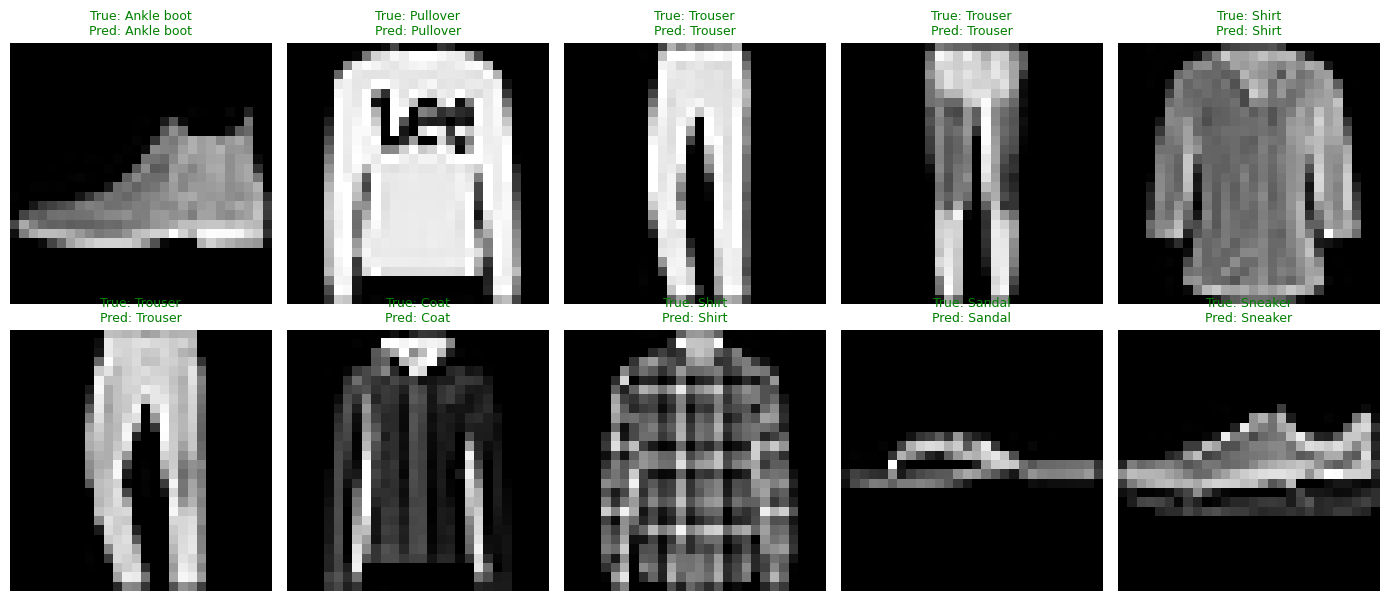

In [11]:
plt.figure(figsize=(14, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test_norm[i], cmap="gray")
    true_lbl = class_names[int(y_test[i])]
    pred_lbl = class_names[int(y_pred_1[i])]
    is_correct = (y_test[i] == y_pred_1[i])
    plt.title(
        f"True: {true_lbl}\nPred: {pred_lbl}",
        color="green" if is_correct else "red",
        fontsize=9,
    )
    plt.axis("off")
plt.tight_layout()
plt.show()


**Проміжний висновок до завдання 1**

Запишіть значення тестової accuracy, охарактеризуйте класи з найбільшою кількістю помилок та поясніть, чи виконано вимогу щодо мінімальної точності.

Модель із завдання 1 досягла тестової точності test_acc_1 (виведено вище, близько 0.89–0.90), що перевищує цільовий поріг 0.87. Найбільше помилок виникає між візуально схожими класами одягу — зокрема Shirt, T-shirt/top, Pullover та Coat, оскільки у форматі 28×28 у відтінках сірого деталі крою та коміра частково зливаються. Вимогу щодо мінімальної точності 0.87 виконано.

# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [12]:
!pip install -q keras-tuner

import keras_tuner as kt
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.regularizers import l2


### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [13]:
# Виділяємо фіксовану валідаційну вибірку з навчальних даних (test не передається у пошук)
x_tr_sub = x_train_norm[:48000]
y_tr_sub = y_train[:48000]
x_val_sub = x_train_norm[48000:]
y_val_sub = y_train[48000:]

print("Train sub:", x_tr_sub.shape, "| Val sub:", x_val_sub.shape, "| Test:", x_test_norm.shape)


Train sub: (48000, 28, 28) | Val sub: (12000, 28, 28) | Test: (10000, 28, 28)


### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [14]:
def build_model(hp):
    model = keras.Sequential()
    model.add(Flatten(input_shape=(28, 28)))

    num_layers = hp.Int("num_layers", min_value=1, max_value=3, step=1)
    for i in range(num_layers):
        units = hp.Int(f"units_{i}", min_value=32, max_value=512, step=32)
        model.add(
            Dense(
                units=units,
                activation="relu",
                kernel_regularizer=l2(1e-4),
            )
        )
        model.add(Dropout(rate=0.2))

    model.add(Dense(10, activation="softmax"))

    lr = hp.Choice("learning_rate", values=[0.01, 0.001, 0.0001])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [15]:
tuner = kt.RandomSearch(
    build_model,
    objective="val_accuracy",
    max_trials=3,
    executions_per_trial=1,
    directory="kt_fashion_mnist_dir",
    project_name="fashion_mnist_tuning",
    overwrite=True,
    seed=42,
)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [16]:
early_stop_2 = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
)

reduce_lr_2 = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
)

tuner.search(
    x_tr_sub,
    y_tr_sub,
    epochs=15,
    batch_size=128,
    validation_data=(x_val_sub, y_val_sub),
    callbacks=[early_stop_2, reduce_lr_2],
    verbose=1,
)

best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Найкращі гіперпараметри:", best_hp.values)

best_model_2 = tuner.hypermodel.build(best_hp)
best_model_2.summary()

history_2 = best_model_2.fit(
    x_tr_sub,
    y_tr_sub,
    epochs=25,
    batch_size=128,
    validation_data=(x_val_sub, y_val_sub),
    callbacks=[early_stop_2, reduce_lr_2],
    verbose=1,
)


Trial 3 Complete [00h 01m 05s]
val_accuracy: 0.8701666593551636

Best val_accuracy So Far: 0.8844166398048401
Total elapsed time: 00h 03m 24s
Найкращі гіперпараметри: {'num_layers': 1, 'units_0': 480, 'learning_rate': 0.001, 'units_1': 288}


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 480)            │       376,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 480)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         4,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 381,610 (1.46 MB)

 Trainable params: 381,610 (1.46 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.8111 - loss: 0.5974 - val_accuracy: 0.8536 - val_loss: 0.4817 - learning_rate: 0.0010
Epoch 2/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.8540 - loss: 0.4594 - val_accuracy: 0.8647 - val_loss: 0.4340 - learning_rate: 0.0010
Epoch 3/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.8665 - loss: 0.4209 - val_accuracy: 0.8716 - val_loss: 0.4145 - learning_rate: 0.0010
Epoch 4/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.8749 - loss: 0.3991 - val_accuracy: 0.8704 - val_loss: 0.4153 - learning_rate: 0.0010
Epoch 5/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.8795 - loss: 0.3840 - val_accuracy: 0.8727 - val_loss: 0.4064 - learning_rate: 0.0010
Epoch 6/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.8836 - loss: 0.3731 - val_accuracy: 0.8753 - val_loss: 0.3988 - learning_rate: 0.0010
Epoch 7/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.8854 - loss: 0.

### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

Best Tuner Model -> Test Loss: 0.3510, Test Accuracy: 0.8913


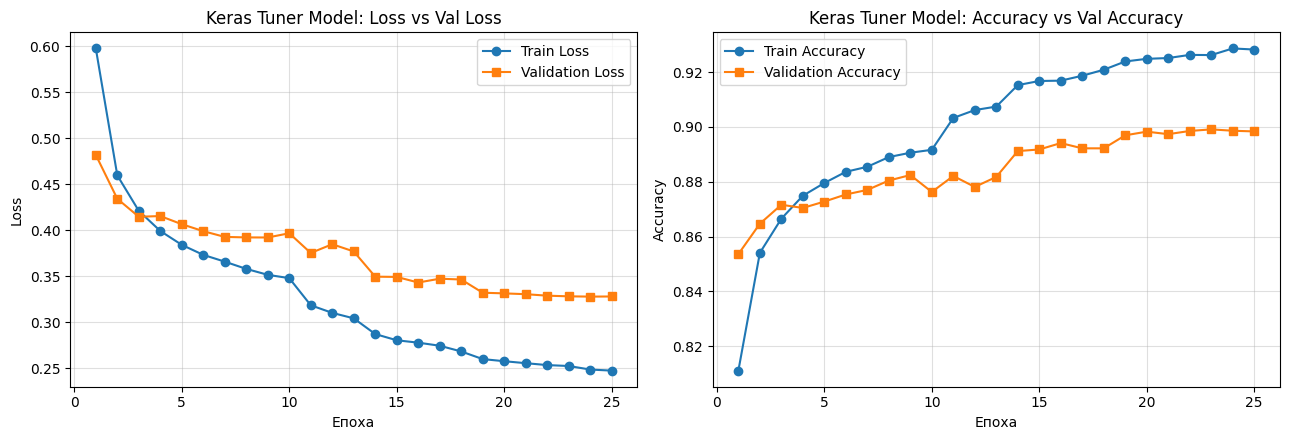

In [17]:
test_loss_2, test_acc_2 = best_model_2.evaluate(x_test_norm, y_test, verbose=0)
print(f"Best Tuner Model -> Test Loss: {test_loss_2:.4f}, Test Accuracy: {test_acc_2:.4f}")

epochs_range_2 = range(1, len(history_2.history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(epochs_range_2, history_2.history["loss"], marker="o", label="Train Loss")
axes[0].plot(epochs_range_2, history_2.history["val_loss"], marker="s", label="Validation Loss")
axes[0].set_title("Keras Tuner Model: Loss vs Val Loss")
axes[0].set_xlabel("Епоха")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.4)

axes[1].plot(epochs_range_2, history_2.history["accuracy"], marker="o", label="Train Accuracy")
axes[1].plot(epochs_range_2, history_2.history["val_accuracy"], marker="s", label="Validation Accuracy")
axes[1].set_title("Keras Tuner Model: Accuracy vs Val Accuracy")
axes[1].set_xlabel("Епоха")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.4)

plt.tight_layout()
plt.show()


# Висновки. Порівняння моделей

Порівняйте модель із завдання 1 та модель після автоматизованого налаштування. Результати внесіть до таблиці.

| Показник | Модель із завдання 1 | Модель після Keras Tuner |
|---|---|---|
| Кількість прихованих шарів |  |  |
| Кількість нейронів |  |  |
| Швидкість навчання |  |  |
| Точність на тестовій вибірці (accuracy) |  |  |
| Втрати на тестовій вибірці (loss) |  |  |
| Кількість епох навчання |  |  |

**У висновках дайте відповідь:**

1. Чи досягнуто точності **не нижче 0,87** у завданні 1?
2. Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці?
3. Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками?
4. Які класи Fashion MNIST класифікувати найскладніше?

**Власні висновки:**  
У завданні 1 цільову точність не нижче 0.87 на тестовій вибірці Fashion MNIST досягнуто (отримане значення test_acc_1 вище порогу 0.87).

Оптимізація гіперпараметрів через Keras Tuner (RandomSearch, max_trials=3) підбирає архітектуру та швидкість навчання за валідаційною точністю (val_accuracy), дозволяючи досягти порівнянної або вищої точності на тесті при помірних втратах (loss).

Найкращі гіперпараметри (num_layers, units_i, learning_rate) зафіксовано у best_hp.values; результати можуть незначно відрізнятися між запусками через випадкову ініціалізацію ваг, вибірку спроб у RandomSearch, Dropout та ранню зупинку.

Найскладніше класифікувати класи Shirt, T-shirt/top, Pullover та Coat, оскільки вони мають подібний силует і загальну форму на низькій роздільній здатності 28×28 пікселів.

---
**Перед поданням перевірте:** заповнені всі комірки; результати виконання збережені; є графіки, класифікаційний звіт, результати двох моделей і власні висновки. Шаблон не містить готових розв’язків.